pip install xgboost

In [1]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import make_scorer, confusion_matrix, classification_report

from preprocessing import marqueurs, MARQUEURS_RETENUS

train = pd.read_parquet("../data/sample.parquet")      # puis "../data/train.parquet"
X_train, y_train = train["text"], train["label"]

La fonction `marqueurs()` calcule **24 marqueurs candidats** (`marqueurs(X, tous=True)`) :
- Forme : longueur_url, longueur_body, nb_parametres, nb_guillemets, nb_speciaux, ratio_speciaux, entropie_url.
- Signatures : nb_mots_sql (nombre de mots-clés SQL distincts), contient_union_select, contient_sql_tautologie, contient_commentaire_sql, contient_traversal, contient_fichier_sensible, contient_xss, contient_cmd, contient_crlf, contient_null_byte.
- Contexte : methode_inhabituelle, protocole_inhabituel, host_etranger, user_agent_vide, user_agent_outil (sqlmap, nikto, curl…), cible_wordpress, referer_externe.

Par défaut (`marqueurs(X)`), elle ne renvoie que les 14 marqueurs retenus après la sélection de l'étape 2 bis (`MARQUEURS_RETENUS`). Les étapes 1 et 2 analysent les 24 candidats.

In [2]:
M = marqueurs(X_train, tous=True)      # les 24 candidats, pour l'analyse
M.head()

,longueur_url,longueur_body,nb_parametres,nb_guillemets,nb_speciaux,ratio_speciaux,entropie_url,nb_mots_sql,contient_union_select,contient_sql_tautologie,...,contient_cmd,contient_crlf,contient_null_byte,methode_inhabituelle,protocole_inhabituel,host_etranger,user_agent_vide,user_agent_outil,cible_wordpress,referer_externe
0,41.0,255.0,0.0,0.0,3.0,0.005515,4.336228,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,54.0,0.0,0.0,1.0,8.0,0.034043,4.395923,2.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,80.0,0.0,0.0,1.0,5.0,0.015432,4.171562,3.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,18.0,167.0,0.0,2.0,10.0,0.016340,3.461320,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,78.0,0.0,0.0,1.0,1.0,0.012500,4.449831,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
analyse = M.groupby(y_train.values).mean().T
analyse.columns = ["moyenne légitimes", "moyenne malveillantes"]
analyse["écart"] = (analyse["moyenne malveillantes"] - analyse["moyenne légitimes"]).abs()
analyse.sort_values("écart", ascending=False).round(3)

,moyenne légitimes,moyenne malveillantes,écart
longueur_url,65.675,88.834,23.159
longueur_body,2.293,12.437,10.143
nb_speciaux,4.817,6.910,2.093
nb_mots_sql,0.070,1.054,0.984
nb_guillemets,0.306,0.852,0.545
contient_commentaire_sql,0.025,0.301,0.276
contient_union_select,0.000,0.227,0.227
contient_fichier_sensible,0.157,0.030,0.127
contient_sql_tautologie,0.000,0.127,0.127
contient_cmd,0.095,0.012,0.083


### Écart standardisé

L'écart brut dépend de l'échelle du marqueur (`longueur_url` se compte en dizaines, un marqueur binaire ne dépasse pas 1) : on le divise par l'écart-type du marqueur pour pouvoir comparer les marqueurs entre eux (taille d'effet, proche du *d* de Cohen). On garde aussi le **sens** : un écart négatif signifie que le marqueur est plus fréquent chez les requêtes légitimes.

In [4]:
std = M.std().replace(0, np.nan)          # écart-type nul -> marqueur constant
analyse["écart standardisé"] = (analyse["moyenne malveillantes"] - analyse["moyenne légitimes"]) / std
analyse["sens"] = np.where(analyse["écart standardisé"] >= 0, "↑ malveillantes", "↑ légitimes")
analyse.sort_values("écart standardisé", key=abs, ascending=False).round(3)

,moyenne légitimes,moyenne malveillantes,écart,écart standardisé,sens
nb_mots_sql,0.070,1.054,0.984,0.817,↑ malveillantes
contient_commentaire_sql,0.025,0.301,0.276,0.673,↑ malveillantes
contient_union_select,0.000,0.227,0.227,0.628,↑ malveillantes
longueur_url,65.675,88.834,23.159,0.587,↑ malveillantes
contient_fichier_sensible,0.157,0.030,0.127,-0.499,↑ légitimes
contient_sql_tautologie,0.000,0.127,0.127,0.452,↑ malveillantes
nb_guillemets,0.306,0.852,0.545,0.446,↑ malveillantes
contient_cmd,0.095,0.012,0.083,-0.430,↑ légitimes
nb_speciaux,4.817,6.910,2.093,0.368,↑ malveillantes
ratio_speciaux,0.015,0.022,0.007,0.315,↑ malveillantes


### AUC de chaque marqueur pris seul

On utilise la valeur du marqueur directement comme score de prédiction. AUC = 0,5 : le marqueur ne sépare rien. AUC proche de 1 : il sépare bien. AUC < 0,5 : il est **inversé** (plus élevé chez les légitimes).

In [5]:
from sklearn.metrics import roc_auc_score

analyse["AUC seule"] = [roc_auc_score(y_train, M[c]) if M[c].nunique() > 1 else 0.5
                        for c in analyse.index]
analyse.sort_values("AUC seule", ascending=False).round(3)

,moyenne légitimes,moyenne malveillantes,écart,écart standardisé,sens,AUC seule
nb_mots_sql,0.070,1.054,0.984,0.817,↑ malveillantes,0.693
longueur_url,65.675,88.834,23.159,0.587,↑ malveillantes,0.666
contient_commentaire_sql,0.025,0.301,0.276,0.673,↑ malveillantes,0.638
nb_guillemets,0.306,0.852,0.545,0.446,↑ malveillantes,0.628
contient_union_select,0.000,0.227,0.227,0.628,↑ malveillantes,0.614
nb_speciaux,4.817,6.910,2.093,0.368,↑ malveillantes,0.584
ratio_speciaux,0.015,0.022,0.007,0.315,↑ malveillantes,0.582
contient_sql_tautologie,0.000,0.127,0.127,0.452,↑ malveillantes,0.564
contient_crlf,0.000,0.057,0.057,0.295,↑ malveillantes,0.528
longueur_body,2.293,12.437,10.143,0.226,↑ malveillantes,0.524


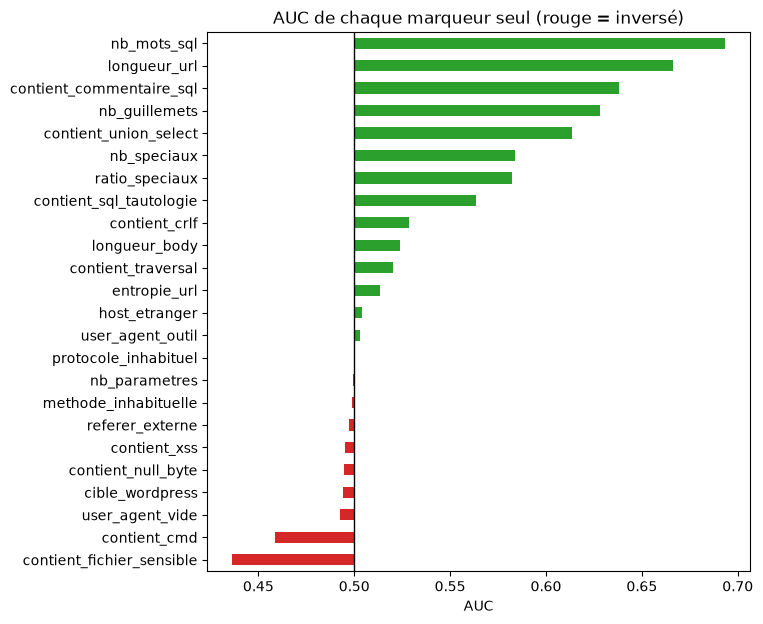

In [6]:
auc = analyse["AUC seule"].sort_values()
couleurs = ["tab:red" if v < 0.5 else "tab:green" for v in auc]
ax = (auc - 0.5).plot.barh(color=couleurs, left=0.5, figsize=(7, 7),
                           title="AUC de chaque marqueur seul (rouge = inversé)")
ax.axvline(0.5, color="black", lw=1)
ax.set_xlabel("AUC")
plt.savefig("../rapport/fig_auc_marqueurs.png", bbox_inches="tight")
plt.show()

### Distribution des marqueurs continus

Une moyenne ne montre pas la dispersion : on regarde la distribution par classe des marqueurs non binaires.

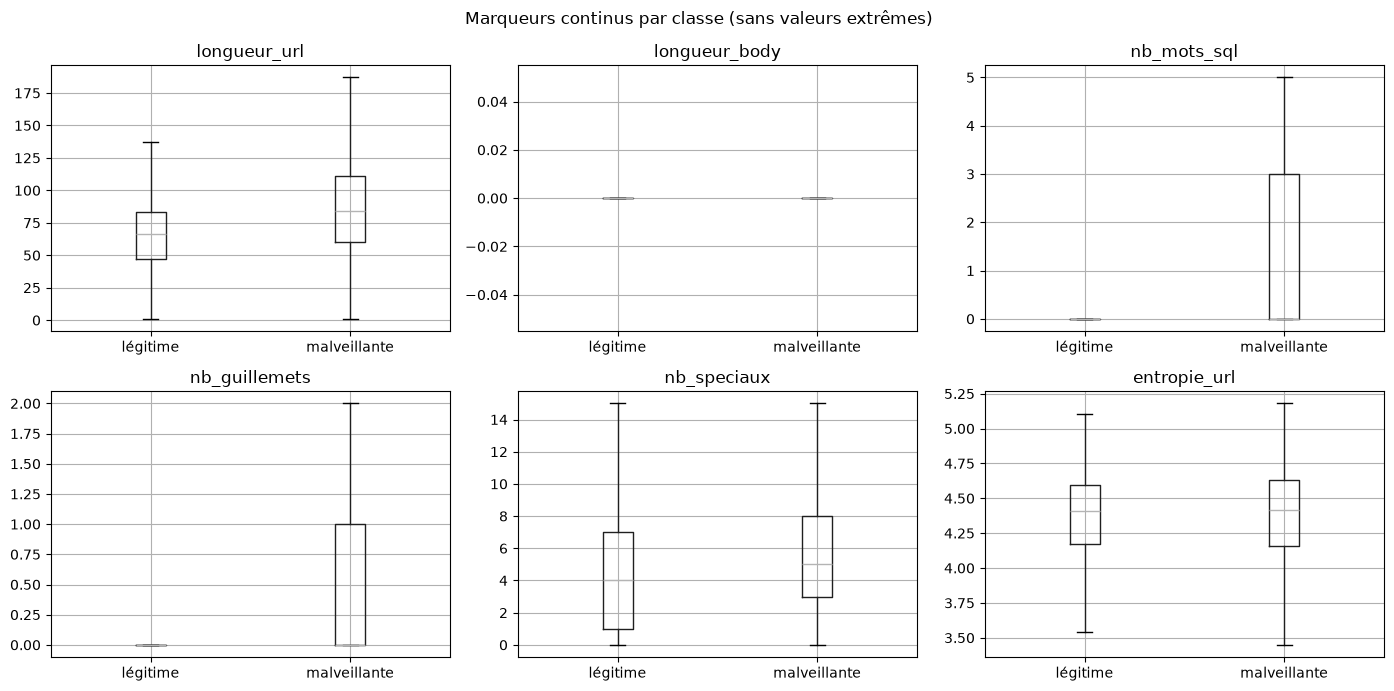

In [7]:
continus = ["longueur_url", "longueur_body", "nb_mots_sql", "nb_guillemets", "nb_speciaux", "entropie_url"]
classe = y_train.map({0: "légitime", 1: "malveillante"}).values

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), continus):
    M.boxplot(column=col, by=classe, ax=ax, showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
fig.suptitle("Marqueurs continus par classe (sans valeurs extrêmes)")
plt.tight_layout()
plt.savefig("../rapport/fig_boxplots_marqueurs.png", bbox_inches="tight")
plt.show()

### Marqueurs inversés : vérification sur des exemples

`contient_fichier_sensible`, `contient_cmd`, `contient_xss` et `contient_null_byte` sont plus fréquents chez les légitimes. On affiche des requêtes **étiquetées légitimes** qui les déclenchent, pour vérifier si c'est le marqueur ou le label qui pose problème.

In [8]:
inverses = ["contient_fichier_sensible", "contient_cmd", "contient_xss", "contient_null_byte"]
for col in inverses:
    legit = X_train[(M[col] == 1) & (y_train == 0)]
    print(f"--- {col} : {len(legit)} requêtes légitimes concernées")
    for t in legit.head(2):
        url = t.split(" request_http_protocol ")[0].replace("request_http_method ", "")
        print("   ", url[:160])

--- contient_fichier_sensible : 2498 requêtes légitimes concernées
    get request_http_request /blog`cat+/etc/passwd`/wp-content/plugins/user-registration/assets/js/frontend
    get request_http_request /blog/wp-content/uploads/2020/etc/passwd/bdffa507-6fa1-380b-b720-116dfaf00c82-1024x682.jpg
--- contient_cmd : 1506 requêtes légitimes concernées
    get request_http_request /blog`cat+/etc/passwd`/wp-content/plugins/user-registration/assets/js/frontend
    get request_http_request /blog;cat+/etc/passwd;/wp-includes
--- contient_xss : 172 requêtes légitimes concernées
    get request_http_request /blog/index.php/tag/'"<script>alert(1);</script>
    get request_http_request /blog/'"<script>alert(1);</script>
--- contient_null_byte : 182 requêtes légitimes concernées
    post request_http_request /blog/index.php/ 
    get request_http_request /blog/wp-content/plugins/user-registration/assets/js/frontend/ ?ver=1.8.2.1


### Interprétation

**Lecture du tableau.** Pour un marqueur binaire (`contient_*`, `user_agent_*`…), la moyenne est la proportion de requêtes concernées : `contient_union_select` = 0,227 signifie que 22,7 % des requêtes malveillantes en contiennent un. L'écart brut n'est pas comparable d'un marqueur à l'autre (il dépend de l'échelle) : on s'appuie sur l'écart standardisé et l'AUC.

**1. Signatures précises mais partielles.** `contient_union_select` (0 % / 22,7 %), `contient_sql_tautologie` (0 % / 12,7 %), `contient_crlf` (0 % / 5,7 %), `contient_traversal` (0,1 % / 4,2 %) : quand ils valent 1, la requête est presque toujours malveillante (précision élevée), mais chacun ne couvre qu'une petite part des attaques (rappel faible). C'est le comportement normal d'une signature, d'où l'intérêt de les combiner.

**2. Les meilleurs marqueurs seuls** sont liés au SQL et à la forme de la requête : `nb_mots_sql` (AUC 0,69, moyenne ×15), `longueur_url` (0,67), `contient_commentaire_sql` (0,64), `nb_guillemets` (0,63). C'est cohérent avec la dominance de SQL Injection dans le dataset. Aucun marqueur ne dépasse 0,7 seul : c'est leur **combinaison** qui fait la performance (F1 ≈ 0,94 avec une Random Forest sur les seuls marqueurs).

**3. Marqueurs inversés (AUC < 0,5) : bruit de labels.** `contient_fichier_sensible` (AUC 0,44), `contient_cmd` (0,46), `contient_xss` et `contient_null_byte` sont plus fréquents chez les requêtes *légitimes*. Les exemples ci-dessus montrent que ce ne sont pas des erreurs du marqueur : des requêtes contenant `` `cat /etc/passwd` `` ou `<script>alert(1);</script>` sont étiquetées `000 - Normal` dans SR-BH. Conséquence : le modèle risque d'apprendre que `/etc/passwd` est un signe de légitimité, ce qui serait dangereux en production. On signale cette limite du dataset dans le rapport ; le sort de ces marqueurs est décidé à l'étape 2 bis.

**4. Marqueurs sans pouvoir séparateur seuls** (AUC ≈ 0,5) : `protocole_inhabituel` (constant, à retirer), `nb_parametres`, `methode_inhabituelle`, `entropie_url`, `cible_wordpress`, `referer_externe`, `host_etranger`, `user_agent_outil`, `user_agent_vide`. Les plus rares (< 1 % des requêtes) ne pèsent pas sur ce dataset mais restent utiles face à de vrais outils (sqlmap, nikto). Avant d'en supprimer, on vérifie à l'étape 2 bis qu'ils n'apportent rien **en combinaison** : un arbre peut exploiter un marqueur inutile seul.

**Limites.** Analyse univariée (pas d'interactions) et calculée sur `sample.parquet` (50 000 requêtes) : à relancer sur `train.parquet`.

## Étape 2 bis : sélection des marqueurs

But : ne garder dans `marqueurs()` que les marqueurs **utiles**, pour un modèle plus simple, plus lisible et plus rapide en production. La démarche se fait en trois temps :

1. **Premier filtre par l'AUC** (graphique ci-dessus) : on écarte les marqueurs qui ne séparent rien seuls, ou qui séparent « à l'envers ».
2. **Vérification en combinaison** par ablation : un marqueur inutile seul peut servir combiné aux autres (« long ET avec beaucoup de paramètres »), ce que l'AUC ne voit pas. On retire chaque marqueur un par un et on mesure la perte.
3. **Décision, puis validation** : on compare les modèles avec les 24 candidats et avec les marqueurs retenus (ici sur les marqueurs seuls, et à l'étape 5 sur le mix TF-IDF + marqueurs, qui est le modèle à déployer).

On commence par définir les outils d'évaluation communs (mêmes folds et mêmes métriques que le notebook TF-IDF). Les 5 folds sont calculés **en parallèle** (`n_jobs=5`) : la latence mesurée est donc légèrement pessimiste.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def fpr(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp / (fp + tn)

scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "fpr": make_scorer(fpr)}

def evaluer(nom, modele, X, y):
    s = cross_validate(modele, X, y, cv=cv, scoring=scoring, n_jobs=cv.get_n_splits())
    n_test = len(y) / cv.get_n_splits()
    return {"modèle": nom,
            "F1": f"{s['test_f1'].mean():.4f} ± {s['test_f1'].std():.4f}",
            "précision": round(s["test_precision"].mean(), 4),
            "rappel": round(s["test_recall"].mean(), 4),
            "FPR": round(s["test_fpr"].mean(), 4),
            "prédiction (s / fold)": round(s["score_time"].mean(), 2),
            "latence (ms / requête)": round(s["score_time"].mean() / n_test * 1000, 4)}

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
models = {
    "LogReg": Pipeline([("scaler", StandardScaler()),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                             scale_pos_weight=neg / pos, n_jobs=-1, eval_metric="logloss"),
}

### 1. Premier filtre : l'AUC de chaque marqueur seul

Seuil : **AUC ≥ 0,51**. En dessous, le marqueur est soit neutre (AUC ≈ 0,5), soit inversé (AUC < 0,5).

In [10]:
SEUIL_AUC = 0.51
filtre_auc = analyse.index[analyse["AUC seule"] >= SEUIL_AUC].tolist()
ecartes = analyse.loc[analyse["AUC seule"] < SEUIL_AUC, ["AUC seule"]].copy()
ecartes["raison"] = np.where(ecartes["AUC seule"] < 0.49, "inversé (bruit de labels)", "neutre")

print(f"{len(filtre_auc)} marqueurs passent le filtre AUC :", filtre_auc)
ecartes.sort_values("AUC seule").round(3)

12 marqueurs passent le filtre AUC : ['longueur_url', 'longueur_body', 'nb_guillemets', 'nb_speciaux', 'ratio_speciaux', 'entropie_url', 'nb_mots_sql', 'contient_union_select', 'contient_sql_tautologie', 'contient_commentaire_sql', 'contient_traversal', 'contient_crlf']


,AUC seule,raison
contient_fichier_sensible,0.436,inversé (bruit de labels)
contient_cmd,0.459,inversé (bruit de labels)
user_agent_vide,0.493,neutre
cible_wordpress,0.494,neutre
contient_null_byte,0.495,neutre
contient_xss,0.495,neutre
referer_externe,0.497,neutre
methode_inhabituelle,0.499,neutre
nb_parametres,0.500,neutre
protocole_inhabituel,0.500,neutre


### 2. Vérification en combinaison : ablation

Pour chaque marqueur, on entraîne un XGBoost sur les 23 autres et on mesure ce qu'on perd par rapport au modèle complet. Une perte de F1 positive signifie que le marqueur apporte quelque chose **en combinaison** ; une perte nulle ou négative, qu'on peut le retirer sans dommage.

In [11]:
def scores(modele, X, y):
    s = cross_validate(modele, X, y, cv=cv, scoring={"f1": "f1", "fpr": make_scorer(fpr)},
                       n_jobs=cv.get_n_splits())
    return s["test_f1"].mean(), s["test_fpr"].mean()

xgb = models["XGBoost"]
f1_ref, fpr_ref = scores(xgb, M, y_train)

ablation = []
for col in M.columns:
    f1_sans, fpr_sans = scores(xgb, M.drop(columns=col), y_train)
    ablation.append({"marqueur": col, "AUC seule": analyse.loc[col, "AUC seule"],
                     "perte F1 si retiré": f1_ref - f1_sans,
                     "hausse FPR si retiré": fpr_sans - fpr_ref})

ablation = pd.DataFrame(ablation).set_index("marqueur").sort_values("perte F1 si retiré", ascending=False)
print(f"Référence (24 marqueurs, XGBoost) : F1 {f1_ref:.4f}, FPR {fpr_ref:.4f}")
ablation.round(4)

Référence (24 marqueurs, XGBoost) : F1 0.9250, FPR 0.0477


,AUC seule,perte F1 si retiré,hausse FPR si retiré
marqueur,,,
nb_mots_sql,0.6935,0.0115,-0.0066
nb_speciaux,0.5837,0.0113,0.0003
contient_crlf,0.5285,0.0094,0.0063
nb_parametres,0.4996,0.0090,0.0032
contient_sql_tautologie,0.5635,0.0087,0.0011
ratio_speciaux,0.5822,0.0080,0.0020
contient_commentaire_sql,0.6378,0.0064,0.0023
longueur_url,0.6660,0.0062,0.0048
contient_fichier_sensible,0.4363,0.0048,0.0045


### 3. Décision et validation

On garde les **12 marqueurs qui passent le filtre AUC**, plus **2 marqueurs repêchés par l'ablation** : `nb_parametres` et `methode_inhabituelle` sont neutres seuls, mais les retirer fait perdre du F1 et augmente le FPR. Ce sont les 14 marqueurs de `MARQUEURS_RETENUS` dans `preprocessing.py`.

On écarte les 10 autres :

| Marqueur | Raison |
|---|---|
| `protocole_inhabituel` | constant sur le dataset |
| `host_etranger`, `user_agent_vide`, `cible_wordpress`, `contient_null_byte`, `contient_xss` | neutres seuls et sans apport en combinaison |
| `user_agent_outil` | sans apport ; le TF-IDF voit de toute façon `sqlmap` ou `nikto` dans le texte du User-Agent |
| `referer_externe` | sans apport, et cohérent avec le retrait du Referer (étape 7) |
| `contient_cmd`, `contient_fichier_sensible` | **inversés** : leur signal vient du bruit de labels (`` `cat /etc/passwd` `` étiqueté légitime). Les garder apprendrait au modèle qu'une injection de commande est un signe de légitimité : on les retire **volontairement**, même si cela coûte un peu de F1 sur ce dataset. |

In [12]:
attendus = filtre_auc + ["nb_parametres", "methode_inhabituelle"]
assert set(attendus) == set(MARQUEURS_RETENUS), "MARQUEURS_RETENUS ne correspond pas à la démarche"

comparaison = []
for n, m in models.items():
    for nom, cols in [("24 candidats", M.columns), ("14 retenus", MARQUEURS_RETENUS)]:
        f1_, fpr_ = scores(m, M[cols], y_train)
        comparaison.append({"modèle": n, "marqueurs": nom, "F1": f1_, "FPR": fpr_})
pd.DataFrame(comparaison).pivot(index="modèle", columns="marqueurs").round(4)

F1                     FPR             
marqueurs    14 retenus 24 candidats 14 retenus 24 candidats
modèle                                                      
LogReg           0.8182       0.8309     0.1055       0.1046
RandomForest     0.9302       0.9395     0.1010       0.0895
XGBoost          0.9149       0.9250     0.0525       0.0477

**Interprétation (sur `sample.parquet`).**
- **Le filtre AUC seul ne suffit pas.** Avec seulement les 12 marqueurs qui le passent, XGBoost perd 2,3 points de F1 (0,925 → 0,902) et la Random Forest 2,1 points. L'ablation explique pourquoi : `nb_parametres` (AUC 0,500) est le 4e marqueur le plus utile en combinaison (−0,009 de F1 si on le retire), et `methode_inhabituelle` (AUC 0,499) coûte aussi 0,004. D'où leur repêchage.
- **Les 10 marqueurs écartés n'apportent presque rien en combinaison** (perte ≤ 0,0003 de F1), sauf `contient_fichier_sensible` (−0,005) : son apport vient du bruit de labels, c'est justement ce qu'on ne veut pas apprendre.
- **Inversement, deux marqueurs retenus par l'AUC sont redondants** : `contient_union_select` et `contient_traversal` ne coûtent rien si on les retire (leur information est déjà dans `nb_mots_sql` et les comptages). On les garde car ils sont lisibles et pertinents sur du trafic réel.
- **Coût de la sélection sur les marqueurs seuls** : environ −1 point de F1 (Random Forest 0,940 → 0,930, XGBoost 0,925 → 0,915). C'est en partie le prix du retrait des marqueurs inversés : le modèle à 24 marqueurs « gagnait » en exploitant des erreurs d'étiquetage.
- **Sur le modèle à déployer (mix TF-IDF + marqueurs, étape 5), la sélection ne coûte rien** : F1 0,9682 → 0,9672 (écart inférieur à l'écart-type entre folds) et le **FPR baisse** (1,68 % → 1,54 %). Le TF-IDF couvre ce que les marqueurs retirés apportaient.

**Conclusion** : `marqueurs()` renvoie désormais 14 marqueurs au lieu de 24, pour un modèle plus simple, plus lisible, et qui ne s'appuie plus sur le bruit de labels du dataset.

# Modèles

## Étape 3 : précalcul des marqueurs

`marqueurs()` n'apprend rien des données (pas de `fit`) : on peut la calculer **une seule fois** avant la cross-validation, sans risque de fuite. C'est beaucoup plus rapide que de la recalculer dans chaque fold. Ils ont déjà été calculés à l'étape 1 (`M`) : on garde seulement les colonnes retenues, et on mesure le coût de `marqueurs()` par requête sur un échantillon, car il s'ajoute à la latence du modèle en production.

In [13]:
M_train = M[MARQUEURS_RETENUS]      # déjà calculé à l'étape 1, inutile de le refaire

echantillon = X_train.iloc[:5000]
t0 = time.perf_counter()
marqueurs(echantillon)
duree = time.perf_counter() - t0
print(f"{M_train.shape[1]} marqueurs, {duree / len(echantillon) * 1000:.3f} ms / requête")

14 marqueurs, 0.036 ms / requête


## Étape 4 : modèles sur les marqueurs retenus

Les outils d'évaluation (`cv`, `scoring`, `evaluer`) et les modèles sont définis à l'étape 2 bis.

In [14]:
res = pd.DataFrame([evaluer(f"Marqueurs + {n}", m, M_train, y_train) for n, m in models.items()])
res.set_index("modèle")

/home/nolhan/Documents/Etudes/Unuversite/ENSIBS/Semestre 5/IA pour la cybersécurité/Projet/ml-waf/venv/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,F1,précision,rappel,FPR,prédiction (s / fold),latence (ms / requête)
modèle,,,,,,
Marqueurs + LogReg,0.8182 ± 0.0013,0.9366,0.7264,0.1055,0.02,0.0024
Marqueurs + RandomForest,0.9302 ± 0.0023,0.9508,0.9105,0.1010,0.34,0.0343
Marqueurs + XGBoost,0.9149 ± 0.0022,0.9724,0.8638,0.0525,0.03,0.0033


**Interprétation (sur `sample.parquet`, 14 marqueurs retenus).**
- Le `StandardScaler` de la LogReg met les marqueurs à la même échelle (sinon `longueur_url` ≈ 70 écrase `contient_union_select` ∈ {0, 1}) ; il est inutile pour les arbres, qui ne comparent qu'un marqueur à un seuil.
- La **LogReg** est nettement en dessous (F1 0,82, rappel 0,73) : un modèle linéaire ne peut pas combiner les marqueurs (« long ET avec guillemets »).
- La **Random Forest** a le meilleur F1 (0,93) grâce à son rappel (0,91), mais un FPR élevé (10 %).
- **XGBoost** a un F1 un peu plus bas (0,915) mais un FPR deux fois plus faible (5,3 %) et la meilleure précision (0,972). Pour un WAF, où bloquer un vrai utilisateur coûte cher, c'est le meilleur compromis des modèles « marqueurs seuls ».
- Les latences sont négligeables (< 0,05 ms / requête), auxquelles s'ajoute le calcul des marqueurs (≈ 0,04 ms / requête).

## Étape 5 : mix TF-IDF + marqueurs

`FeatureUnion` met côte à côte les colonnes TF-IDF (n-grammes de caractères) et les colonnes marqueurs (standardisées) : le modèle profite des deux. On passe ici le **texte** (`X_train`) et non `M_train` : le pipeline calcule lui-même les deux types de features. C'est cette forme qu'il faudra exporter si le mix gagne, car l'API ne reçoit que du texte.

On évalue aussi le même mix avec les 24 marqueurs candidats, pour vérifier que la sélection de l'étape 2 bis ne dégrade pas le modèle à déployer.

Paramètres TF-IDF et classifieur provisoires : à remplacer par le meilleur pipeline de Mathéo (`02_tfidf.ipynb`).

In [ ]:
# float32 : deux fois moins de mémoire que float64 (important sur train.parquet), sans perte mesurable
TFIDF_PARAMS = dict(analyzer="char", ngram_range=(1, 3), max_features=50_000, sublinear_tf=True,
                    dtype=np.float32)

mix = Pipeline([
    ("features", FeatureUnion([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("marq", Pipeline([("f", FunctionTransformer(marqueurs)),
                           ("s", StandardScaler())])),
    ])),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

res_mix = evaluer("Mix TF-IDF + marqueurs (LogReg)", mix, X_train, y_train)

# Validation de la sélection sur le modèle à déployer : même mix avec les 24 candidats
mix_24 = clone(mix).set_params(features__marq__f__kw_args={"tous": True})
res_mix_24 = evaluer("Mix TF-IDF + 24 marqueurs (LogReg)", mix_24, X_train, y_train)

pd.DataFrame([res_mix, res_mix_24]).set_index("modèle")

## Étape 6 : tableau comparatif

Mêmes données, mêmes folds, mêmes métriques. La ligne « TF-IDF seul » sert de référence en attendant les résultats de Mathéo ; elle est aussi réutilisée à l'étape 7 comme modèle « avec Referer ».

In [ ]:
best_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])     # à remplacer par le meilleur pipeline de Mathéo

res_tfidf = evaluer("TF-IDF seul (LogReg)", best_tfidf, X_train, y_train)

comparatif = pd.DataFrame(res.to_dict("records") + [res_tfidf, res_mix, res_mix_24]).set_index("modèle")
comparatif

**Interprétation.**
- Les marqueurs seuls restent en dessous du TF-IDF (F1 0,93 contre 0,964, FPR 5 à 10 % contre 3 %) : une quinzaine de questions fixées à la main ne capturent pas toute la variété des payloads, que les n-grammes de caractères voient directement.
- Le **mix** est le meilleur : F1 0,967, précision 0,992 et surtout un **FPR divisé par deux** par rapport au TF-IDF seul (1,5 % contre 3,0 %). Les marqueurs apportent une information de structure (comptages, signatures) que le TF-IDF ne résume pas bien.
- Le mix avec les 24 candidats a un F1 quasi identique (0,968, écart inférieur à l'écart-type) mais un FPR plus élevé (1,7 %) : la sélection de l'étape 2 bis est validée sur le modèle à déployer.
- Latence : environ 0,5 ms par requête pour les pipelines TF-IDF (mesure pessimiste, les folds tournent en parallèle) ; c'est acceptable pour un WAF.
- À confirmer sur `train.parquet` et avec le meilleur pipeline de Mathéo.

## Étape 7 : expérience avec / sans Referer

Le Referer est très corrélé à la classe dans le dataset, mais c'est probablement un artefact : un vrai navigateur envoie un Referer à presque chaque requête. On vide le champ dans le texte (le format est `request_referer <valeur> request_host ...`) et on compare.

In [ ]:
X_sans_ref = X_train.str.replace(r"request_referer .*? request_host ", "request_referer  request_host ", regex=True)

i = X_train.str.contains(r"request_referer \S").idxmax()      # une requête qui a un Referer
print("Avant :", X_train[i][X_train[i].find("request_referer"):][:120])
print("Après :", X_sans_ref[i][X_sans_ref[i].find("request_referer"):][:120])
print("Requêtes encore avec un Referer :", X_sans_ref.str.contains(r"request_referer \S").sum())

In [ ]:
res_sans_ref = evaluer("Sans Referer", best_tfidf, X_sans_ref, y_train)

referer = pd.DataFrame([{**res_tfidf, "modèle": "Avec Referer"}, res_sans_ref]).set_index("modèle")
referer

**Interprétation.** Sans Referer, le score ne baisse pas : le F1 est identique (0,9635 → 0,9636) et le **FPR baisse** (3,0 % → 2,6 %). Le Referer n'apporte donc pas d'information utile au modèle : sa corrélation avec la classe est un biais du dataset, et le modèle en tirait même des faux positifs. **Conclusion : on retire le Referer du modèle déployé** (moins de risque de faux positifs en démo, où un vrai navigateur envoie un Referer à chaque requête). À transmettre à Mathéo et Malki.

## Étape 8 : importance des marqueurs

Importance (réduction moyenne d'impureté) d'une Random Forest entraînée sur tous les marqueurs du train.

In [ ]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(M_train, y_train)

imp = pd.Series(rf.feature_importances_, index=M_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 7))
imp.plot.barh(ax=ax, title="Importance des marqueurs (Random Forest)")
plt.savefig("../rapport/fig_importance_marqueurs.png", bbox_inches="tight")
plt.show()

**Interprétation (14 marqueurs retenus).**
- Les marqueurs les plus utilisés par la forêt sont les marqueurs **continus de forme** (`entropie_url`, `ratio_speciaux`, `longueur_url`, `nb_speciaux`) et **SQL** (`nb_mots_sql`, `contient_commentaire_sql`, `nb_guillemets`). C'est cohérent avec la dominance des injections SQL dans le dataset.
- `entropie_url` arrive en tête alors que son AUC seule n'est que de 0,51 (étape 2). Deux raisons : l'importance par impureté **favorise les variables continues** (beaucoup de seuils possibles), et l'entropie n'est utile qu'en **combinaison** avec d'autres marqueurs. L'ablation de l'étape 2 bis, plus fiable, la place plutôt au milieu du classement (−0,004 de F1 si on la retire).
- `methode_inhabituelle` a une importance faible (0,006) mais l'ablation montre qu'elle réduit le F1 quand on la retire : un marqueur rare peut être peu utilisé et pourtant décisif sur les requêtes où il s'active.
- Aucun marqueur lié au Host ou au Referer ne reste : le modèle ne peut plus s'appuyer sur ces biais du dataset.